In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
sns_colors = sns.color_palette("tab10")

from pymatgen.core.structure import Structure

from ase.io import read, Trajectory
from ase.visualize import view
from pymatgen.io.ase import AseAtomsAdaptor

from gnome_dreams_oer_screening import OER_catalyst_study

# Rutile TiO2 used for testing:
# TiO2 = read("ZrO2_m.cif")
TiO2 = read("TiO2_rutile.cif")
TiO2_structure = AseAtomsAdaptor.get_structure(TiO2)

# Example GNoME structures contaning Ir:
test_cands = Trajectory('test_cands.traj')
if True:
    view(TiO2)

In [2]:
# Find plane of surface metal atoms ~ rughly
# Any O atoms way above? - whould these surfaces be disregarded?
# Select surface sites based on O atoms above surface plane
# Select on-top surface sites

In [3]:
cand = TiO2 # test_cands[-1]

In [4]:
study = OER_catalyst_study(cand,     
    H2O_gas_free_energy = -14.217,
    H2_gas_free_energy = -6.77
)
study.set_relaxed_structure(cand)

In [5]:
study.identify_distinct_surfaces(max_miller = 1)

In [6]:
study.predict_most_likely_surfaces(max_miller = 1)
df = study.get_termination_rankings()
# df.sort_values('Normalized score', ascending=False)
df

,Miller indices,Termination index,Score,Normalized score
0,"(1, 1, 1)",0,-0.279671,0.021723
1,"(1, 1, 1)",1,-0.279671,0.021723
2,"(1, 1, 0)",2,-0.103895,1.000000
3,"(1, 0, 1)",3,-0.238485,0.250942
4,"(1, 0, 0)",4,-0.146930,0.760490
5,"(0, 0, 1)",5,-0.283574,0.000000


In [7]:
study.get_init_adsorption_site_df(termination_index=0)

,site type,ad site element,ad site neighboring elements,reduced coordination,position,G_approx(O),G(O),G_approx(OH),G(OH),G_approx(OOH),G(OOH)
1,on-top,Ti,"[(O, 1.9518096083479366), (O, 1.95180960834793...",N/A,"[3.082857722966928, 1.9826999215405692, 15.983...",None,None,None,None,None,None
2,lattice O,N/A,"[(Ti, 1.9518096083479375), (Ti, 3.492789173289...",2,"[0.6983665237530797, 0.14475320546559386, 13.8...",None,None,None,None,None,None
3,lattice O,N/A,"[(Ti, 1.951809608347939), (Ti, 1.9796564765795...",1,"[0.7935154588505939, 4.454480199990663, 12.773...",None,None,None,None,None,None


In [9]:
view(study.get_init_adsorption_sites_atoms(termination_index=0))

<Popen: returncode: None args: ['c:\\Users\\matnis\\OneDrive - Danmarks Tekn...>

### --->>> Need method for getting specific termination !!!

In [7]:
atoms_list = [AseAtomsAdaptor.get_atoms(s) for s in study.terminations.values()]

# view(atoms_list)

In [8]:
from gnome_dreams_oer_screening.oer.ad_site_determination import (
    determine_surface_plane, determine_adsorption_sites)

,site type,ad site element,ad site neighboring elements,reduced coordination,position,G_approx(O),G(O),G_approx(OH),G(OH),G_approx(OOH),G(OOH)
0,on-top,Ti,"[(O, 1.951809608347936), (O, 1.951809608347936...",N/A,"[1.4796067800000003, 4.270518461424494, 14.718...",None,None,None,None,None,None
1,on-top,Ti,"[(O, 1.9518096083479364), (O, 1.95180960834793...",N/A,"[-3.311838709094295e-17, 1.0811051314143296, 1...",None,None,None,None,None,None
2,lattice O,N/A,"[(Ti, 1.9518096083479368), (Ti, 1.951809608347...",1,"[1.4796067800000001, 0.8875227549160024, 14.38...",None,None,None,None,None,None


In [24]:
df['ad site neighboring elements'][2]

[('Ti', np.float64(1.9518096083479366)),
 ('Ti', np.float64(1.9518096083479366)),
 ('Ti', np.float64(3.4927891732896987)),
 ('Ti', np.float64(3.4927891732896987))]

In [10]:
df['ad site neighboring elements'].values[-2]

[('Sc', np.float64(2.06855895800209)), ('Sc', np.float64(2.0685594823678066))]

In [ ]:
study.initialize_oer_surface_study(0)
surface_study_dict = study.get_surface_studies() 

In [9]:
sur_study = surface_study_dict[1]

KeyError: 1

In [ ]:
view(sur_study.get_non_relaxed_surface())
# coord-numbers for test (1,1,0) - top: Ti: 1:-1, 1: -3, O: 1: -1

<Popen: returncode: None args: ['c:\\Users\\matnis\\OneDrive - Danmarks Tekn...>

In [ ]:
stody = OER_catalyst_study(
    TiO2,
    H2O_gas_free_energy = -14.217,
    H2_gas_free_energy = -6.77
)

0.0036363636363636364

In [ ]:
print(36/(36+8+7+3+2) - 35/(35+8+7+3+2) < 0.2/(35+8+7+3+2))

False


In [26]:
stody.identify_distinct_surfaces()
df = stody.get_df_with_surface_rankings()
df

,miller_indices
0,"(1, 1, 1)"
1,"(1, 1, 0)"
2,"(1, 0, 1)"
3,"(1, 0, 0)"
4,"(0, 0, 1)"


In [27]:
stody.identify_distinct_surfaces()
stody.predict_most_likely_surfaces('coordination', 'stoichiometric')
df = stody.get_df_with_surface_rankings()
df

{(1, 1, 1): [-0.01165294639491824, -0.010196328095553459], (1, 1, 0): [-0.0064934609674087655, -0.004328973978272511], (1, 0, 1): [-0.00993687390323602, -0.013249165204314694], (1, 0, 0): [-0.009183140566849794, -0.006122093711233196], (0, 0, 1): [-0.011815580507881089]}


,miller_indices,Scores,Max Score,Normalized Score
0,"(1, 1, 1)","[-0.01165294639491824, -0.010196328095553459]",-0.010196,0.216287
1,"(1, 1, 0)","[-0.0064934609674087655, -0.004328973978272511]",-0.004329,1.000000
2,"(1, 0, 1)","[-0.00993687390323602, -0.013249165204314694]",-0.009937,0.250942
3,"(1, 0, 0)","[-0.009183140566849794, -0.006122093711233196]",-0.006122,0.760490
4,"(0, 0, 1)",[-0.011815580507881089],-0.011816,0.000000


In [28]:
Energies = (np.array([0.75, 0.76, 1.11, 1.51, 1.51]) - 0.75)/(1.51- 0.75)
millers = [(1,1,0), (1,0,0), (1,0,1), (1,1,1), (0,0,1)]

In [29]:
cord_dict = {}

for i, row in df.iterrows():
    cord_dict[row['miller_indices']] = row['Scores']

coords = []
for miller in millers:
    coords.append(np.max(cord_dict[miller]))


max_coords = -0.013249165204314694
normed_coords = -(coords - np.max(coords)) / (np.max(coords) - np.min(coords))

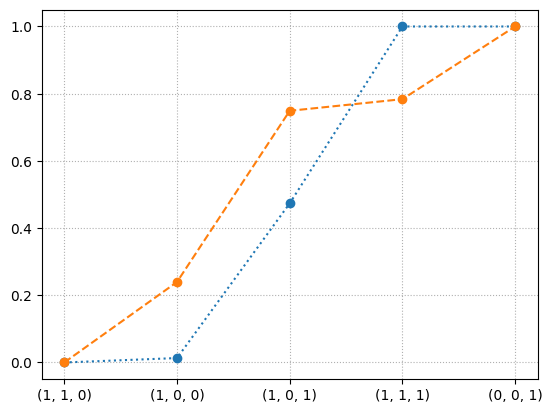

In [30]:
plt.plot(Energies, 'o:', color = sns_colors[0])
plt.plot(normed_coords, 'o--', color = sns_colors[1])
plt.xticks(ticks=np.arange(len(millers)), labels=millers);
plt.grid(linestyle=':')

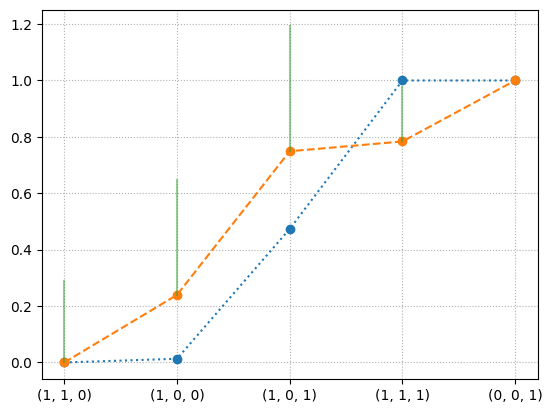

In [31]:
plt.plot(Energies, 'o:', color = sns_colors[0])
plt.plot(normed_coords, 'o--', color = sns_colors[1])
plt.xticks(ticks=np.arange(len(millers)), labels=millers);
plt.grid(linestyle=':')
for i, miller in enumerate(millers):
    plt.plot(np.ones(len(cord_dict[miller])) * i, -np.array(cord_dict[miller]-np.max(coords)) / (np.max(coords) - np.min(coords)), '-', color = sns_colors[2], alpha=0.5)

In [32]:
# stody.initialize_OER_surface_studies((1,1,1))

stody.OER_surface_studies[(1,1,1)]

KeyError: (1, 1, 1)

In [ ]:
type(df.values[0][0])

tuple

In [ ]:
stody._set_bulk_coordination('coordination')
stody.bulk_structure.site_properties.get('bulk-custom-coord')

[8, 8, 3, 3, 3, 3]

In [ ]:
for atom in stody.bulk_atoms:
    print(atom.index, atom.symbol)

0 Ti
1 Ti
2 O
3 O
4 O
5 O


In [ ]:
stody._determine_coordination_numbers(test_cands[0], 'coordination')

[0, 0, 0, 0, 6, 6, 6, 6, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 0]